# Survival Analysis

When we are testing a new medical treatment regimen, we’re not only interested in whether the treatment works or not. What we want is the probability of how long this treatment will remain effective. In other words, let’s say we have a cancer drug: we don’t just want to know whether or not people survive when on this medication, but rather the probability of longevity, i.e., how long they are likely to survive if they are on this treatment. That’s the fundamental idea behind survival analysis. In this approach, we try to measure "time-to-event" as a set of probabilities and estimate the chances of a particular event happening over time.

## Censored data

Imagine a clinical trial where a patient moves away, drops out of the study, or is still alive and cancer-free when the research period officially concludes. We don’t know their exact long-term outcome, but we do know they survived up to that specific point. Standard statistical methods would throw out or skew this incomplete data, but survival analysis ingeniously incorporates these "censored" observations—meaning that instead of throwing away incomplete records or making false assumptions, it makes full use of every bit of available data. In addition to maximally utilizing data, censoring ensures the elimination of hidden biases. For instance, if people dropped out because they felt better and moved on, throwing them out would make the drug look worse than it is. Conversely, if sicker people dropped out, keeping them out artificially inflates success rates. Censoring accounts for when people leave without assuming why they left.

## Types of Censoring

Not all censoring looks the same, and survival analysis generally classifies missing data into three distinct categories. **Right-censoring** is by far the most common; this happens when a study ends or a participant drops out before the event occurs, meaning we only know their survival time is at least as long as the time they were observed. **Left-censoring** occurs in the opposite scenario, where the target event actually happened before the observation period even began, so we only know it occurred sometime prior to a certain point. Finally, **interval-censoring** happens when subjects are not monitored continuously but instead checked in periodically (like during medical check-ups every six months), meaning we know the event happened, but only that it occurred somewhere within a specific time window between two visits.

In [1]:
#| include: false
library(tidyverse)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


| User ID | Months Observed ($t$) | Status | What actually happened? (The Story) |
| :--- | :--- | :--- | :--- |
| **User 1** | 12.0 | **1 (Event)** | Replaced battery at month 12 because it degraded. |
| **User 2** | 24.0+ | **0 (Censored)** | Study ended at 24 months. Phone was still working fine! |
| **User 3** | 8.5 | **1 (Event)** | Heavy gamer; replaced battery early at month 8.5. |
| **User 4** | 14.2 | **0 (Censored)** | Upgraded to a new phone at month 14 just for a better camera (battery hadn't failed yet). |
| **User 5** | 18.2 | **1 (Event)** | Replaced battery at month 18.2. |
| **User 6** | 6.0 | **0 (Censored)** | Lost their phone at month 6 (dropped it); dropped out of the study. |

In [3]:
#| include: false
install.packages("kableExtra")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘svglite’





Attaching package: ‘kableExtra’


The following object is masked from ‘package:dplyr’:

    group_rows




user_id,time_start,time_end,status_code
1,0,12.0,1
2,0,24.0,0
3,0,8.5,1
4,0,14.2,0
5,0,18.2,1
6,0,6.0,0
7,0,6.0,1
8,10,15.0,1
9,12,20.0,1
10,0,24.0,0


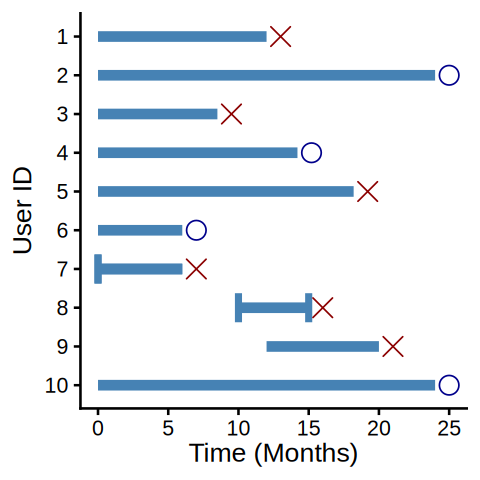

In [4]:
#| fig-cap: "Plot showing survival events based on the table on the left. Eight out of ten users show right censoring, User ID 7 is an example of left censoring while User ID 8 depicts interval censoring. `X` indicates occurence of the event that is the phone battery was replaced."
#| label: fig-survival-taxonomy
#| layout: [[50,50]]
#| warning: false
#| message: false
#| echo: false
options(repr.plot.width = 4, repr.plot.height = 4)

library(ggplot2)
library(dplyr)
library(kableExtra)
library(IRdisplay)

# 1. Create the complete 10-user masterclass data frame
battery_df <- data.frame(
  user_id = 1:10,
  time_start = c(0, 0, 0, 0, 0, 0, 0, 10.0, 12.0, 0),
  time_end   = c(12.0, 24.0, 8.5, 14.2, 18.2, 6.0, 6.0, 15.0, 20.0, 24.0),
  status_code = c(1, 0, 1, 0, 1, 0, 2, 3, 1, 0),
  # 1 = Exact Event, 0 = Right-Censored, 2 = Left-Censored, 3 = Interval, 4 = Competing Risk
  censoring_type = factor(
    c("Exact Event", "Right-Censored", "Exact Event",
      "Right-Censored", "Exact Event", "Right-Censored",
      "Left-Censored", "Interval-Censored", "Left-Truncated", "Right-Censored"),
    levels = c("Exact Event", "Right-Censored", "Left-Censored", "Interval-Censored", "Left-Truncated", "Competing Risk")
  ),
  story = c(
    "Replaced battery at month 12 because it degraded.",
    "Study ended at 24 months. Phone was still working fine!",
    "Heavy gamer; replaced battery early at month 8.5.",
    "Upgraded to a new phone at month 14 just for a better camera.",
    "Replaced battery at month 18.2.",
    "Lost their phone at month 6; dropped out of the study.",
    "Battery was already degraded when checked at month 6.",
    "Battery was good at month 10, but failed by inspection at month 15.",
    "Joined study late at month 12 with working phone; battery failed at month 20.",
    "Study ended at 24 months. Phone was still working fine!"
  )
)

# Reverse user_id factor so User 1 appears at the top of the plot
battery_df$user_factor <- factor(
  battery_df$user_id,
  levels = rev(battery_df$user_id)
)

#### Show table ####
html_table <- battery_df |>
  select("user_id",	"time_start",	"time_end",	"status_code") |>
  mutate(status_code = if_else(status_code %in% c(2, 3), 1, status_code)) |>
  kable(format = "html",
        caption = "Summary of time intervals and phone battery status codes for different users.") |>
  kable_styling(
    bootstrap_options = c("bordered", "hover", "condensed"),
    full_width = FALSE
  )

display_html(paste(html_table, collapse = "\n"))
#### Done table ####

# 2. Create the Enhanced Swimmer Plot
ggplot(battery_df, aes(y = user_factor)) +
  # Draw baseline tracking lines from time_start to time_end
  geom_segment(aes(x = time_start, xend = time_end, yend = user_factor),
               color = "steelblue", linewidth = 3) +

  # Uncertainty span bars for Interval & Left censoring
  geom_errorbar(data = subset(battery_df, status_code == 3),
                aes(xmin = time_start, xmax = time_end, y = user_factor),
                orientation = "y",
                width = 0.75, color = "steelblue", linewidth = 2) +
  geom_segment(data = subset(battery_df, status_code == 2),
             aes(x = time_start, xend = time_end, y = user_factor, yend = user_factor),
             color = "steelblue", linewidth = 3) +

  # Single vertical tick aligning correctly with User 7
  geom_errorbar(data = subset(battery_df, status_code == 2),
                aes(xmin = time_start, xmax = time_start, y = user_factor),
                orientation = "y", width = 0.75, color = "steelblue", linewidth = 2) +

  # Exact Events & Left-Truncated events (Red Dots)
  geom_point(data = subset(battery_df, status_code %in% c(1)),
             aes(x = time_end + 1), color = "darkred", size = 5, shape = 4) +

  # Right-Censored (Blue Plus Signs)
  geom_point(data = subset(battery_df, status_code == 0),
             aes(x = time_end + 1), color = "darkblue", size = 5, shape = 1) +

  # Left-Censored / Interval endpoints
  geom_point(data = subset(battery_df, status_code %in% c(2,3)),
             aes(x = time_end + 1), color = "darkred", size = 5, shape = 4) +

  # Labels and Theme
  labs(
    x = "Time (Months)",
    y = "User ID"
  ) +
  theme_classic(base_size = 16)

In [ ]:
#| include: false
install.packages(c("survival", "survminer"))

In [ ]:
library(survival)
library(survminer)
head(lung)

Loading required package: ggplot2

Loading required package: ggpubr


Attaching package: ‘survminer’


The following object is masked from ‘package:survival’:

    myeloma




,inst,time,status,age,sex,ph.ecog,ph.karno,pat.karno,meal.cal,wt.loss
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,3,306,2,74,1,1,90,100,1175,NA
2,3,455,2,68,1,0,90,90,1225,15
3,3,1010,1,56,1,0,90,90,NA,15
4,5,210,2,57,1,1,90,60,1150,11
5,1,883,2,60,1,0,100,90,NA,0
6,12,1022,1,74,1,1,50,80,513,0


Call: survfit(formula = Surv(time, status) ~ sex, data = lung)

                sex=1 
 time n.risk n.event survival std.err lower 95% CI upper 95% CI
   11    138       3   0.9783  0.0124       0.9542        1.000
   12    135       1   0.9710  0.0143       0.9434        0.999
   13    134       2   0.9565  0.0174       0.9231        0.991
   15    132       1   0.9493  0.0187       0.9134        0.987
   26    131       1   0.9420  0.0199       0.9038        0.982
   30    130       1   0.9348  0.0210       0.8945        0.977
   31    129       1   0.9275  0.0221       0.8853        0.972
   53    128       2   0.9130  0.0240       0.8672        0.961
   54    126       1   0.9058  0.0249       0.8583        0.956
   59    125       1   0.8986  0.0257       0.8496        0.950
   60    124       1   0.8913  0.0265       0.8409        0.945
   65    123       2   0.8768  0.0280       0.8237        0.933
   71    121       1   0.8696  0.0287       0.8152        0.928
   81    120     

Ignoring unknown labels:
• colour : "Strata"


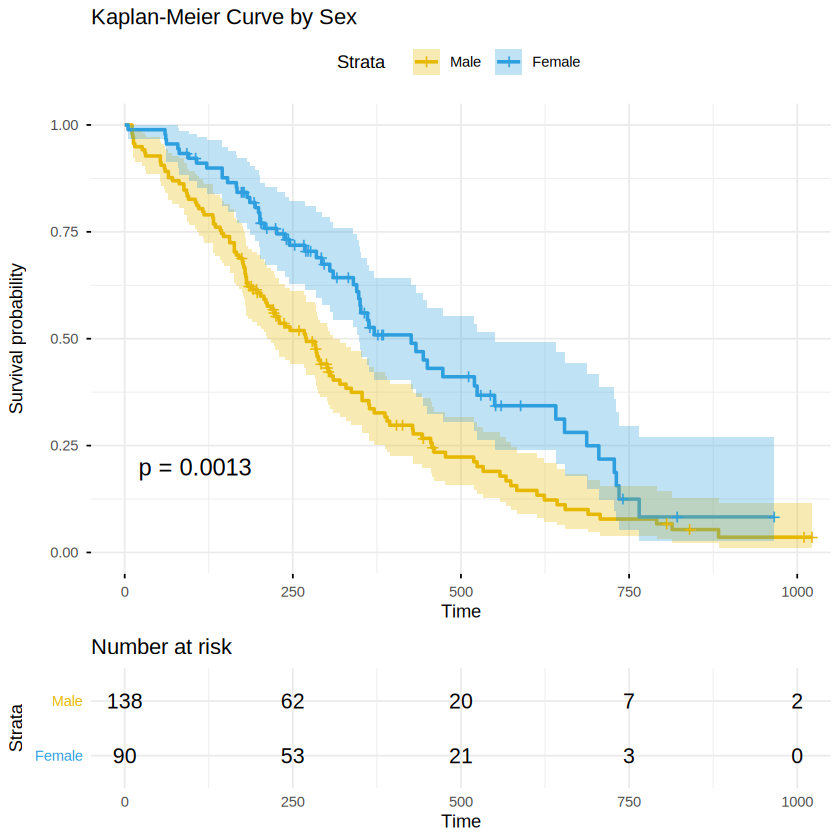

In [ ]:
# 1. Create the Surv object and fit the Kaplan-Meier model
km_fit <- survfit(Surv(time, status) ~ sex, data = lung)

# 2. View a summary of the model
summary(km_fit)

# 3. Plot the survival curves with a risk table and p-value
ggsurvplot(
  km_fit,
  data = lung,
  pval = TRUE,             # Adds the log-rank test p-value
  conf.int = TRUE,         # Adds confidence intervals
  risk.table = TRUE,       # Adds risk table below the plot
  legend.labs = c("Male", "Female"),
  palette = c("#E7B800", "#2E9FDF"),
  ggtheme = theme_minimal(),
  title = "Kaplan-Meier Curve by Sex"
)

In [ ]:
log_rank_test <- survdiff(Surv(time, status) ~ sex, data = lung)
print(log_rank_test)

Call:
survdiff(formula = Surv(time, status) ~ sex, data = lung)

        N Observed Expected (O-E)^2/E (O-E)^2/V
sex=1 138      112     91.6      4.55      10.3
sex=2  90       53     73.4      5.68      10.3

 Chisq= 10.3  on 1 degrees of freedom, p= 0.001 


In [ ]:
# Fit the Cox model with multiple predictors
cox_fit <- coxph(Surv(time, status) ~ age + sex + ph.ecog, data = lung)

# View the model summary and hazard ratios
summary(cox_fit)

Call:
coxph(formula = Surv(time, status) ~ age + sex + ph.ecog, data = lung)

  n= 227, number of events= 164 
   (1 observation deleted due to missingness)

             coef exp(coef)  se(coef)      z Pr(>|z|)    
age      0.011067  1.011128  0.009267  1.194 0.232416    
sex     -0.552612  0.575445  0.167739 -3.294 0.000986 ***
ph.ecog  0.463728  1.589991  0.113577  4.083 4.45e-05 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

        exp(coef) exp(-coef) lower .95 upper .95
age        1.0111     0.9890    0.9929    1.0297
sex        0.5754     1.7378    0.4142    0.7994
ph.ecog    1.5900     0.6289    1.2727    1.9864

Concordance= 0.637  (se = 0.025 )
Likelihood ratio test= 30.5  on 3 df,   p=1e-06
Wald test            = 29.93  on 3 df,   p=1e-06
Score (logrank) test = 30.5  on 3 df,   p=1e-06


        chisq df    p
age     0.188  1 0.66
sex     2.305  1 0.13
ph.ecog 2.054  1 0.15
GLOBAL  4.464  3 0.22


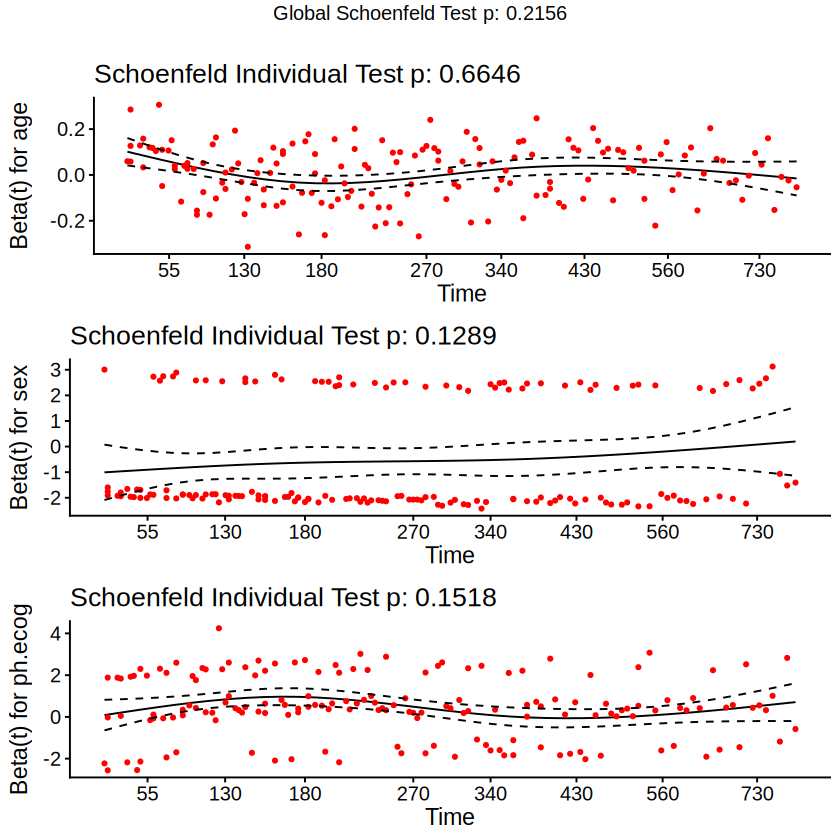

In [ ]:
# Test proportional hazards assumption
test_ph <- cox.zph(cox_fit)
print(test_ph)

# Plot the residuals to visually check assumption
ggcoxzph(test_ph)